# Speckle and how to reduce it: polarization, wavelength and angle diversity

A laser spot on a wall glitters. The grainy pattern, **speckle**, is not a
flaw of the laser. A matte surface is rough on the scale of the
wavelength, so every point reflects the light with a random phase. Any
imaging system, a camera or the eye, adds up the light from one
resolution cell. With coherent light the result is a random sum of
phasors, which is bright in some places and dark in others. This makes
speckle the main problem of laser illumination: in laser projectors, in
laser-lit microscopes and inspection tools, and in lithography with
excimer lasers.

The contrast $C = \sigma_I/\langle I\rangle$ of fully developed speckle
is exactly 1. It drops only when the detector adds the intensities of
several patterns that are, at least in part, uncorrelated. There are three
places to find such patterns: two **polarizations**, several
**wavelengths** and several **illumination angles** (a moving diffuser).
This notebook builds each one with wave optics and checks it against the
theory in Goodman's book.

The module `pyoptics.speckle` has the simulation helpers. They are
`rough_surface()`, `coherent_image()` and `diffuser_field()`. It also has
the theory: `speckle_pdf()`, `speckle_autocorrelation()`,
`summed_contrast()`, `polarization_contrast()`, `wavelength_correlation()`,
`spectral_contrast()`, `angular_diversity_contrast()` and
`moving_diffuser_contrast()`.

The sections are:

1. fully developed speckle: statistics and grain size,
2. the sum of $M$ patterns and the square root law,
3. polarization diversity,
4. wavelength diversity, with surfaces, volume scatterers, fibres and multi-line lasers,
5. angle diversity: a moving diffuser and its limit,
6. a speckle budget for a laser projector.

All simulations image a rough surface (rms height $\sigma_h = 10$ µm,
much larger than $\lambda = 532$ nm) with a coherent, aberration-free
system of numerical aperture NA = 0.05, on a grid of $512^2$ samples,
0.5 µm apart.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import speckle as sp
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(87)

WL = 0.532          # um, a green laser
DX, N = 0.5, 512    # um, grid: 256 um across
NA = 0.05           # observer: grain lambda/NA = 10.6 um
SIGMA_H, ELL = 10.0, 0.5   # rough surface: rms height and correlation length (um)

def surface():
    return sp.rough_surface(N, DX, SIGMA_H, ELL, rng)

def image(h, wavelength=WL, illumination=1.0, NA_obs=NA):
    """Speckle intensity of a rough surface h in reflection, observer pupil fixed at NA/WL."""
    return np.abs(sp.coherent_image(illumination*np.exp(4j*np.pi*h/wavelength), DX, NA_obs, WL))**2

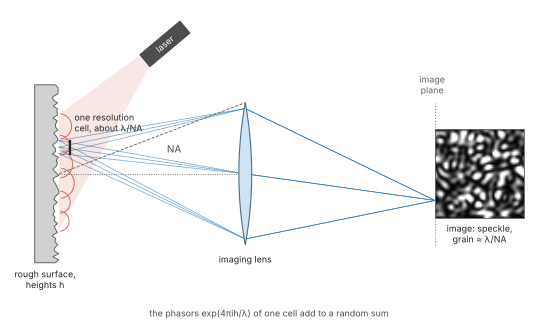

In [2]:
fig, ax = plt.subplots(figsize=(13, 5.2))
sketch.speckle_formation(ax)
plt.show()

## 1. Fully developed speckle

The field in the image is a sum of very many contributions with
independent, uniformly distributed phases. By the central limit theorem it
is a circular complex Gaussian variable, so its intensity follows the
exponential density

$$p(I) = \frac{1}{\langle I\rangle}\exp\left(-\frac{I}{\langle I\rangle}\right),$$

whose standard deviation equals its mean ($C = 1$). The most likely
intensity is zero. The size of the grains comes from the pupil. The
intensity autocorrelation is
$\langle I(x)I(x+r)\rangle/\langle I\rangle^2 = 1 + |\mu(r)|^2$, and $\mu$
is the Fourier transform of the pupil. For a circular pupil that is the
Airy amplitude $2J_1(v)/v$ with $v = 2\pi\,\mathrm{NA}\,r/\lambda$. The
first zero, $0.61\lambda/\mathrm{NA}$, is the radius of a grain.

In [3]:
h = surface()
I_a = image(h, NA_obs=0.05)
I_b = image(h, NA_obs=0.1)
for name, I, na in (("NA 0.05", I_a, 0.05), ("NA 0.10", I_b, 0.1)):
    print("{}: contrast {:.3f}, grain radius 0.61 lambda/NA = {:.1f} um".format(name, sp.speckle_contrast(I), 0.61*WL/na))
r_a, g_a = sp.intensity_autocorrelation(I_a, DX)
r_b, g_b = sp.intensity_autocorrelation(I_b, DX)
# mean over several surfaces for smooth statistics
I_many = np.concatenate([image(surface()).ravel() for _ in range(4)])
print("mean over 4 surfaces: contrast {:.3f}, fraction below mean/10: {:.3f} (exponential: {:.3f})"
      .format(sp.speckle_contrast(I_many), np.mean(I_many < 0.1*I_many.mean()), 1 - np.exp(-0.1)))

NA 0.05: contrast 1.000, grain radius 0.61 lambda/NA = 6.5 um
NA 0.10: contrast 0.991, grain radius 0.61 lambda/NA = 3.2 um
mean over 4 surfaces: contrast 1.005, fraction below mean/10: 0.095 (exponential: 0.095)


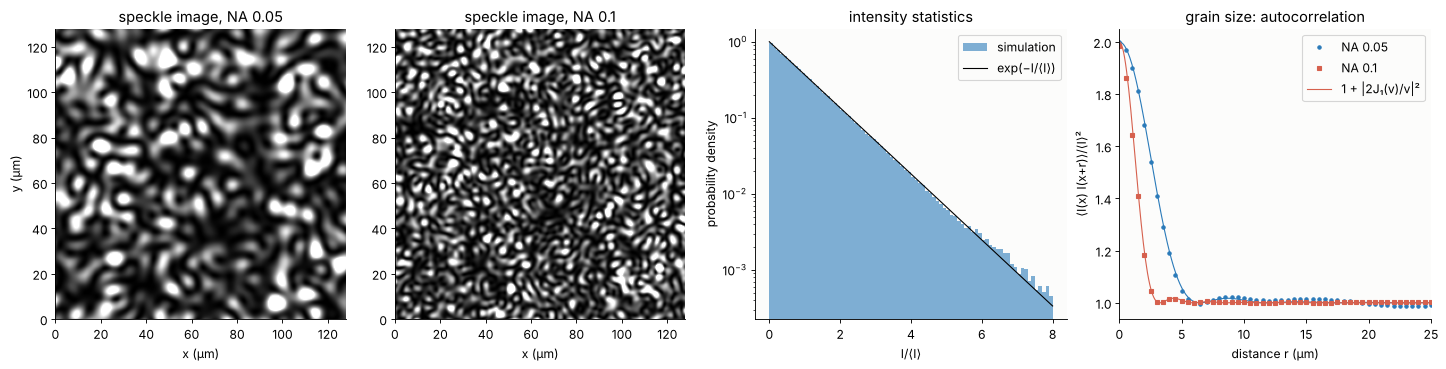

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5), layout="constrained")
ext = [0, N*DX, 0, N*DX]
for a, I, t in ((ax[0], I_a, "NA 0.05"), (ax[1], I_b, "NA 0.1")):
    a.imshow(I/I.mean(), extent=ext, cmap="gray", vmin=0, vmax=3, origin="lower")
    a.set_xlim(0, 128)
    a.set_ylim(0, 128)
    a.set_xlabel("x (µm)")
    a.set_title("speckle image, " + t)
ax[0].set_ylabel("y (µm)")
Ib = np.linspace(0, 8, 200)
ax[2].hist(I_many/I_many.mean(), bins=80, range=(0, 8), density=True, color=BLUE, alpha=0.6, label="simulation")
ax[2].semilogy(Ib, sp.speckle_pdf(Ib), color="k", lw=1, label="exp(−I/⟨I⟩)")
ax[2].set_xlabel("I/⟨I⟩")
ax[2].set_ylabel("probability density")
ax[2].set_title("intensity statistics")
ax[2].legend()
rr = np.linspace(0, 25, 300)
ax[3].plot(r_a, g_a, "o", ms=3, color=BLUE, label="NA 0.05")
ax[3].plot(rr, sp.speckle_autocorrelation(rr, 0.05, WL), color=BLUE, lw=1)
ax[3].plot(r_b, g_b, "s", ms=3, color=RED, label="NA 0.1")
ax[3].plot(rr, sp.speckle_autocorrelation(rr, 0.1, WL), color=RED, lw=1, label="1 + |2J₁(v)/v|²")
ax[3].set_xlim(0, 25)
ax[3].set_xlabel("distance r (µm)")
ax[3].set_ylabel("⟨I(x) I(x+r)⟩/⟨I⟩²")
ax[3].set_title("grain size: autocorrelation")
ax[3].legend()
plt.show()

The simulated contrast is 1.00, and 9.5 % of the pixels have less than a
tenth of the mean intensity, just as the exponential law predicts
($1 - e^{-0.1} = 0.095$). Doubling the NA halves the grain, and the
autocorrelations of both images follow $1 + |2J_1(v)/v|^2$. Note what
does *not* appear here: the roughness. Once $\sigma_h$ is well above
$\lambda/4$ the phases are uniformly random, and neither the height nor
the roughness spectrum matters any more. The only way to reduce the
contrast is to add patterns.

## 2. Adding patterns: the square root law

The intensity of a sum of $M$ independent speckle patterns of equal mean
follows a gamma density of order $M$,

$$p(I) = \frac{M^M I^{M-1}}{\Gamma(M)\langle I\rangle^M}\exp\left(-M\frac{I}{\langle I\rangle}\right),\qquad C = \frac{1}{\sqrt M}.$$

The patterns are rarely independent in practice. For $M$ patterns of equal
mean intensity whose fields are correlated with the coefficients
$\mu_{ij}$, Goodman's result is

$$C^2 = \frac{\sum_{ij}|\mu_{ij}|^2}{M^2} = \frac{\sum_n \lambda_n^2}{\left(\sum_n\lambda_n\right)^2},$$

where $\lambda_n$ are the eigenvalues of the matrix $\mu$
(`sp.summed_contrast()`). $M$ correlated patterns act like
$1/C^2 = (\sum\lambda_n)^2/\sum\lambda_n^2$ independent ones. Section 4
tests this with a multi-line laser.

In [5]:
Ms = [1, 2, 4, 16]
sums = {}
for M in Ms:
    sums[M] = np.concatenate([sum(image(surface()) for _ in range(M)).ravel() for _ in range(2)])
    print("M = {:2d} independent patterns: contrast {:.3f}, 1/sqrt(M) = {:.3f}".format(M, sp.speckle_contrast(sums[M]), 1/np.sqrt(M)))

M =  1 independent patterns: contrast 0.999, 1/sqrt(M) = 1.000
M =  2 independent patterns: contrast 0.699, 1/sqrt(M) = 0.707


M =  4 independent patterns: contrast 0.506, 1/sqrt(M) = 0.500


M = 16 independent patterns: contrast 0.251, 1/sqrt(M) = 0.250


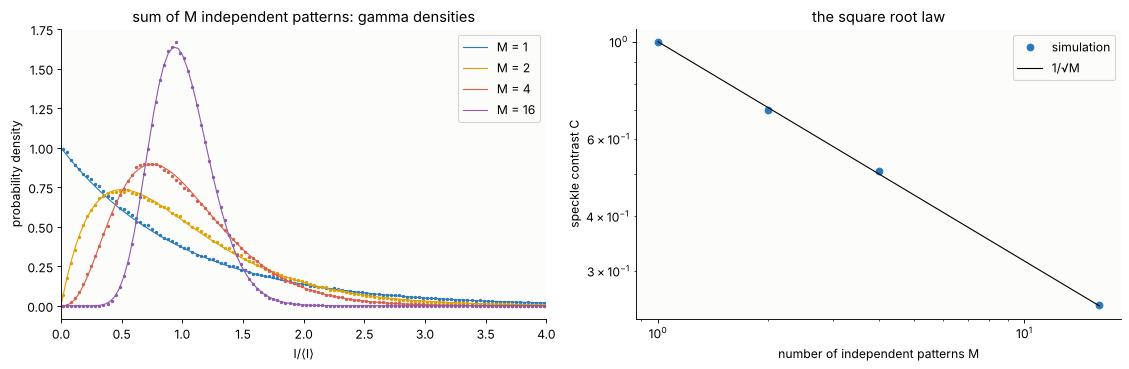

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for M, c in zip(Ms, (BLUE, ORANGE, RED, PURPLE)):
    I = sums[M]/sums[M].mean()
    hist, e = np.histogram(I, bins=120, range=(0, 4), density=True)
    ax[0].plot(0.5*(e[1:] + e[:-1]), hist, ".", color=c, ms=4)
    ax[0].plot(Ib, sp.speckle_pdf(Ib, 1.0, M), color=c, lw=1, label="M = {}".format(M))
ax[0].set_xlim(0, 4)
ax[0].set_xlabel("I/⟨I⟩")
ax[0].set_ylabel("probability density")
ax[0].set_title("sum of M independent patterns: gamma densities")
ax[0].legend()
Mm = np.arange(1, 17)
ax[1].loglog(Ms, [sp.speckle_contrast(sums[M]) for M in Ms], "o", color=BLUE, label="simulation")
ax[1].loglog(Mm, 1/np.sqrt(Mm), color="k", lw=1, label="1/√M")
ax[1].set_xlabel("number of independent patterns M")
ax[1].set_ylabel("speckle contrast C")
ax[1].set_title("the square root law")
ax[1].legend()
plt.show()

Sums of independent patterns from different surfaces follow the gamma
densities and $1/\sqrt M$ to about 1 %. The densities also show why a
small $M$ already helps the eye. With $M = 4$ the dark pixels are
gone, because the most likely intensity moves from zero to
$(1 - 1/M)\langle I\rangle$. The square root law is slow, however: a
contrast of 4 % needs more than 600 independent patterns.

## 3. Polarization diversity

A surface that scatters many times (paper, white paint, a projection
screen with a volume diffuser) depolarizes the light. The two orthogonal
polarizations then carry independent speckle patterns. A detector without
a polarizer, such as the eye, adds them. For scattered light with the
degree of polarization $P$, the intensities of the two patterns are
$(1 \pm P)/2$ of the total, and

$$C = \sqrt{\frac{1 + P^2}{2}},$$

which is $1/\sqrt2$ at best.

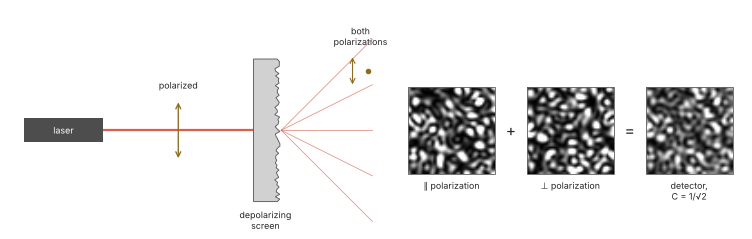

In [7]:
fig, ax = plt.subplots(figsize=(14, 3.6))
sketch.speckle_diversity(ax, "polarization")
plt.show()

In [8]:
Ps = np.linspace(0, 1, 6)
C_pol = []
for P in Ps:
    cs = []
    for _ in range(2):
        Ix, Iy = image(surface()), image(surface())
        cs.append(sp.speckle_contrast((1 + P)/2*Ix + (1 - P)/2*Iy))
    C_pol.append(np.mean(cs))
for P, c in zip(Ps, C_pol):
    print("degree of polarization {:.1f}: contrast {:.3f}, sqrt((1 + P^2)/2) = {:.3f}".format(P, c, sp.polarization_contrast(P)))

degree of polarization 0.0: contrast 0.701, sqrt((1 + P^2)/2) = 0.707
degree of polarization 0.2: contrast 0.718, sqrt((1 + P^2)/2) = 0.721
degree of polarization 0.4: contrast 0.767, sqrt((1 + P^2)/2) = 0.762
degree of polarization 0.6: contrast 0.822, sqrt((1 + P^2)/2) = 0.825
degree of polarization 0.8: contrast 0.922, sqrt((1 + P^2)/2) = 0.906
degree of polarization 1.0: contrast 0.992, sqrt((1 + P^2)/2) = 1.000


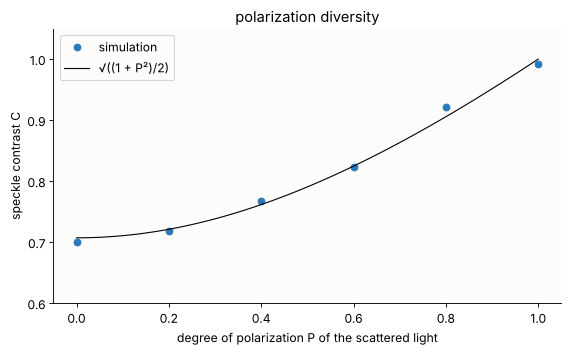

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.3), layout="constrained")
pp = np.linspace(0, 1, 100)
ax.plot(Ps, C_pol, "o", color=BLUE, label="simulation")
ax.plot(pp, sp.polarization_contrast(pp), color="k", lw=1, label="√((1 + P²)/2)")
ax.set_xlabel("degree of polarization P of the scattered light")
ax.set_ylabel("speckle contrast C")
ax.set_ylim(0.6, 1.05)
ax.set_title("polarization diversity")
ax.legend()
plt.show()

The simulation follows the formula. Polarization buys at most a
factor of $\sqrt2$, and only on a depolarizing screen. Metallic
(polarization-preserving) screens, used for polarization-coded 3D
cinema, give it away entirely.

## 4. Wavelength diversity

A path $L$ through the scatterer adds the phase $kL$. If the wavenumber
changes by $\Delta k = 2\pi\Delta\lambda/\lambda^2$, the phase changes by
$\Delta k\,L$. The speckle pattern changes once these changes, spread over
the paths that meet in one image point, reach about one radian. For
Gaussian distributed paths of rms spread $\sigma_L$, the field correlation
is the characteristic function of the path distribution, and

$$|\mu(\Delta\lambda)|^2 = \exp\left(-(\Delta k\,\sigma_L)^2\right).$$

For a rough surface in reflection at normal incidence $L = 2h$, so
$\sigma_L = 2\sigma_h$. Averaging over a Gaussian spectrum of rms width
$\sigma_\lambda$ gives the closed form

$$C = \left[1 + \left(\frac{4\pi\,\sigma_L\,\sigma_\lambda}{\lambda^2}\right)^2\right]^{-1/4}.$$

The simulation keeps the observer's pupil fixed and changes only the
wavelength in the phase $4\pi h/\lambda$. The scaling of the grain with
$\lambda$ is a separate effect, and it is negligible for
$\Delta\lambda/\lambda \sim 10^{-3}$.

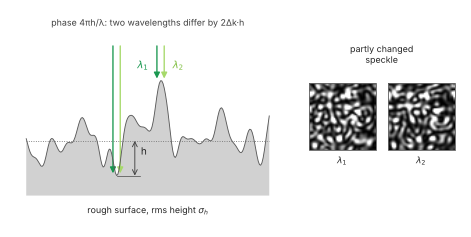

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.speckle_diversity(ax, "wavelength")
plt.show()

In [11]:
# correlation of the speckle at two wavelengths (sigma_h = 10 um: sigma_L = 20 um)
dls = np.linspace(0, 0.004, 9)            # um
rho = []
for dl in dls:
    rs = []
    for _ in range(2):
        hh = surface()
        rs.append(np.corrcoef(image(hh).ravel(), image(hh, WL + dl).ravel())[0, 1])
    rho.append(np.mean(rs))
for dl, r in zip(dls, rho):
    print("delta lambda {:.1f} nm: intensity correlation {:.3f}, exp(-(dk sigma_L)^2) = {:.3f}"
          .format(1e3*dl, r, sp.wavelength_correlation(dl, WL, 2*SIGMA_H)))
# a Gaussian spectrum of rms width sigma_lambda, sampled by 61 lines
sig_l = np.array([0.25, 0.5, 1.0, 2.0, 4.0])*1e-3
C_spec = []
for s in sig_l:
    lam = WL + np.linspace(-3*s, 3*s, 61)
    S = np.exp(-(lam - WL)**2/(2*s**2))
    cs = []
    for _ in range(2):
        hh = surface()
        cs.append(sp.speckle_contrast(sum(w*image(hh, l) for w, l in zip(S, lam))))
    C_spec.append(np.mean(cs))
for s, c in zip(sig_l, C_spec):
    print("rms width {:.2f} nm: contrast {:.3f}, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = {:.3f}"
          .format(1e3*s, c, sp.spectral_contrast(s, WL, 2*SIGMA_H)))
# a laser with 5 lines, spaced delta apart: Goodman's formula with the correlation matrix
lines = {}
for delta in (0.5e-3, 1e-3, 2e-3, 4e-3):
    lam = WL + (np.arange(5) - 2)*delta
    mu2 = sp.wavelength_correlation(lam[:, None] - lam[None, :], WL, 2*SIGMA_H)
    cs = []
    for _ in range(2):
        hh = surface()
        cs.append(sp.speckle_contrast(sum(image(hh, l) for l in lam)))
    lines[delta] = (np.mean(cs), sp.summed_contrast(np.sqrt(mu2)), np.linalg.eigvalsh(np.sqrt(mu2)))
    print("5 lines {:.1f} nm apart: contrast {:.3f}, sqrt(sum |mu_ij|^2)/5 = {:.3f}, eigenvalues {}"
          .format(1e3*delta, lines[delta][0], lines[delta][1], np.round(lines[delta][2][::-1], 2)))

delta lambda 0.0 nm: intensity correlation 1.000, exp(-(dk sigma_L)^2) = 1.000
delta lambda 0.5 nm: intensity correlation 0.950, exp(-(dk sigma_L)^2) = 0.952
delta lambda 1.0 nm: intensity correlation 0.816, exp(-(dk sigma_L)^2) = 0.821
delta lambda 1.5 nm: intensity correlation 0.640, exp(-(dk sigma_L)^2) = 0.642
delta lambda 2.0 nm: intensity correlation 0.464, exp(-(dk sigma_L)^2) = 0.455
delta lambda 2.5 nm: intensity correlation 0.287, exp(-(dk sigma_L)^2) = 0.292
delta lambda 3.0 nm: intensity correlation 0.164, exp(-(dk sigma_L)^2) = 0.170
delta lambda 3.5 nm: intensity correlation 0.090, exp(-(dk sigma_L)^2) = 0.089
delta lambda 4.0 nm: intensity correlation 0.045, exp(-(dk sigma_L)^2) = 0.043


rms width 0.25 nm: contrast 0.989, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = 0.988
rms width 0.50 nm: contrast 0.946, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = 0.956
rms width 1.00 nm: contrast 0.870, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = 0.865
rms width 2.00 nm: contrast 0.688, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = 0.700
rms width 4.00 nm: contrast 0.518, (1 + (4 pi sigma_L sigma_lambda/lambda^2)^2)^(-1/4) = 0.521
5 lines 0.5 nm apart: contrast 0.905, sqrt(sum |mu_ij|^2)/5 = 0.917, eigenvalues [4.57 0.42 0.02 0.   0.  ]


5 lines 1.0 nm apart: contrast 0.773, sqrt(sum |mu_ij|^2)/5 = 0.776, eigenvalues [3.72 1.11 0.16 0.01 0.  ]
5 lines 2.0 nm apart: contrast 0.595, sqrt(sum |mu_ij|^2)/5 = 0.597, eigenvalues [2.43 1.55 0.73 0.24 0.05]


5 lines 4.0 nm apart: contrast 0.458, sqrt(sum |mu_ij|^2)/5 = 0.462, eigenvalues [1.36 1.21 1.   0.79 0.64]


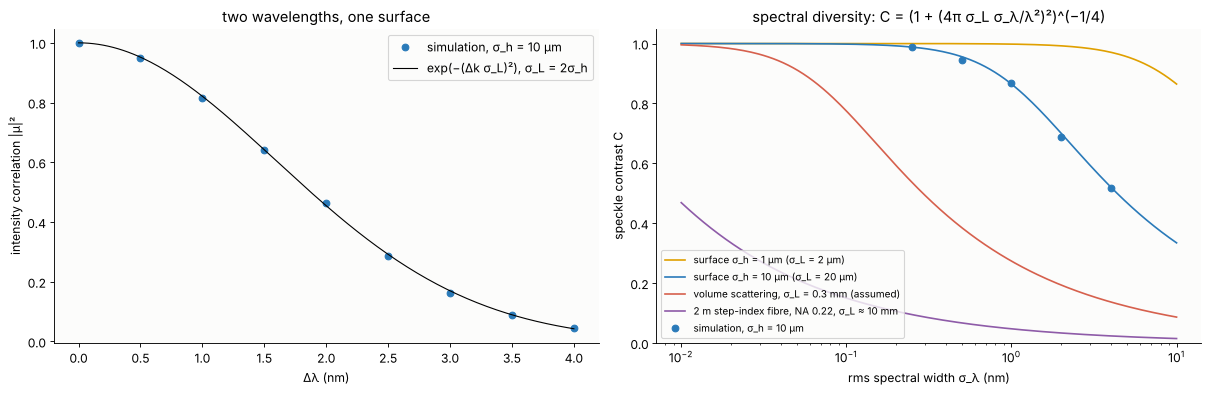

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
dd = np.linspace(0, 4, 200)*1e-3
ax[0].plot(1e3*dls, rho, "o", color=BLUE, label="simulation, σ_h = 10 µm")
ax[0].plot(1e3*dd, sp.wavelength_correlation(dd, WL, 2*SIGMA_H), color="k", lw=1, label="exp(−(Δk σ_L)²), σ_L = 2σ_h")
ax[0].set_xlabel("Δλ (nm)")
ax[0].set_ylabel("intensity correlation |μ|²")
ax[0].set_title("two wavelengths, one surface")
ax[0].legend()
ss = np.logspace(-2, 1, 200)*1e-3
cases = ((2.0, "surface σ_h = 1 µm (σ_L = 2 µm)", ORANGE),
         (20.0, "surface σ_h = 10 µm (σ_L = 20 µm)", BLUE),
         (300.0, "volume scattering, σ_L = 0.3 mm (assumed)", RED),
         (1e4, "2 m step-index fibre, NA 0.22, σ_L ≈ 10 mm", PURPLE))
for sL, t, c in cases:
    ax[1].semilogx(1e3*ss, sp.spectral_contrast(ss, WL, sL), color=c, label=t)
ax[1].semilogx(1e3*sig_l, C_spec, "o", color=BLUE, label="simulation, σ_h = 10 µm")
ax[1].set_xlabel("rms spectral width σ_λ (nm)")
ax[1].set_ylabel("speckle contrast C")
ax[1].set_ylim(0, 1.05)
ax[1].set_title("spectral diversity: C = (1 + (4π σ_L σ_λ/λ²)²)^(−1/4)")
ax[1].legend(fontsize=9, loc="lower left")
plt.show()

The correlation of the patterns follows $\exp(-(\Delta k\sigma_L)^2)$
within the scatter of the simulation (left). The contrast for a Gaussian
spectrum, sampled by 61 lines, matches the closed form to within 2 %
(right, dots).

The curves on the right show how much the path spread matters. A surface
with $\sigma_h = 1$ µm hardly reacts even to a 10 nm wide spectrum. A
volume scatterer with millimetre-scale paths, or a multimode fibre,
needs only a fraction of a nanometre. In a step-index fibre the steepest
guided ray travels $L\,\mathrm{NA}^2/(2n)$ further than the axial one:
33 mm for 2 m of fibre with NA 0.22. With the paths spread evenly over that
range, $\sigma_L \approx 33/\sqrt{12} \approx 10$ mm. This is why a long
multimode fibre and a laser a few nanometres wide make low-speckle
illumination for microscopes.

A laser with five lines tests Goodman's formula with correlated patterns.
The contrast it predicts from the correlation matrix $|\mu_{ij}|$ agrees
with the simulation to within 0.012 in all four cases. Closely spaced
lines are almost one pattern: at 0.5 nm spacing one eigenvalue carries
4.6 of the total of 5. The full $1/\sqrt5 = 0.447$ needs lines
far enough apart that the eigenvalues become equal (0.458 at 4 nm).

## 5. Angle diversity: a moving diffuser

A diffuser in front of a condenser lights the object from every direction
within $\mathrm{NA}_\mathrm{ill}$. Each position of a moving diffuser
gives another illumination, a random speckle field with grains of
$\lambda/\mathrm{NA}_\mathrm{ill}$, and so another speckle pattern of the
object. The detector integrates over many positions.

How much this helps is limited by the observer, not by the number of
positions. Two illumination directions give independent object speckle
only if they differ by more than the observer's aperture. Averaged over
infinitely many positions, the contrast that remains for a rough object
is

$$C_\infty^2 = \frac{\iint |h(\mathbf a)|^2\,|h(\mathbf b)|^2\,|J(\mathbf a-\mathbf b)|^2\,d\mathbf a\,d\mathbf b}{\left(\int|h|^2\right)^2},$$

where $h$ is the observer's amplitude point spread function and $J$ the
mutual intensity of the illumination, $2J_1(v)/v$ with
$v = 2\pi\,\mathrm{NA_{ill}}\,r/\lambda$ (`sp.angular_diversity_contrast()`).
For $\mathrm{NA_{ill}} \gg \mathrm{NA_{obs}}$ the double integral becomes
the coherence area $\lambda^2/(\pi\mathrm{NA_{ill}}^2)$ of the
illumination divided by the effective area of $|h|^2$. For circular
pupils, $C_\infty \to \sqrt{1 - 16/(3\pi^2)}\;\mathrm{NA_{obs}}/\mathrm{NA_{ill}}
= 0.678\,\mathrm{NA_{obs}}/\mathrm{NA_{ill}}$, which is a little better
than the naive count of $(\mathrm{NA_{ill}}/\mathrm{NA_{obs}})^2$ cells.

With $M$ independent diffuser positions the same calculation, with
Gaussian statistics for both the object and the illumination, gives

$$C_M^2 = C_\infty^2 + \frac{1 + C_\infty^2}{M}.$$

One position ($M = 1$) gives $\sqrt{1 + 2C_\infty^2} > 1$. The speckled
illumination modulates the object's speckle (product speckle), and a
diffuser that stands still makes things worse than a clean laser beam.

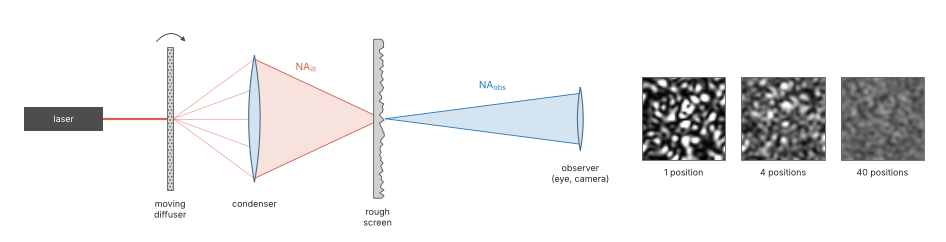

In [13]:
fig, ax = plt.subplots(figsize=(15, 3.8))
sketch.speckle_diversity(ax, "angle")
plt.show()

In [14]:
ratios = [0.5, 1.0, 2.0, 4.0]
M_max, reps = 64, 3
Ms5 = np.array([1, 2, 4, 8, 16, 32, 64])
C_M, C_inf, snaps = {}, {}, {}
for q in ratios:
    C_inf[q] = sp.angular_diversity_contrast(q*NA, NA, WL)
    runs = []
    for rep in range(reps):
        r_obj = np.exp(4j*np.pi*surface()/WL)
        acc, cs = 0.0, []
        for m in range(1, M_max + 1):
            u = sp.diffuser_field(N, DX, q*NA, WL, rng)          # one diffuser position
            acc = acc + np.abs(sp.coherent_image(r_obj*u, DX, NA, WL))**2
            if m in Ms5:
                cs.append(sp.speckle_contrast(acc))
                if q == 2.0 and rep == 0:
                    snaps[m] = acc/m
        runs.append(cs)
    C_M[q] = np.mean(runs, axis=0)
    print("NA_ill/NA_obs = {:.1f}: C_inf = {:.3f}; M = {}: simulated C {}, theory {}".format(
        q, C_inf[q], Ms5.tolist(), np.round(C_M[q], 3).tolist(), np.round(sp.moving_diffuser_contrast(Ms5, C_inf[q]), 3).tolist()))
q_th = np.logspace(-1.3, 1.3, 25)
C_inf_curve = np.array([sp.angular_diversity_contrast(q*NA, NA, WL, n=1024 if q < 5 else 2048) for q in q_th])
print("C_inf * NA_ill/NA_obs at ratio {:.0f}: {:.3f} (limit sqrt(1 - 16/(3 pi^2)) = {:.3f})".format(q_th[-1], C_inf_curve[-1]*q_th[-1], sp.ANGULAR_LIMIT))

NA_ill/NA_obs = 0.5: C_inf = 0.729; M = [1, 2, 4, 8, 16, 32, 64]: simulated C [1.47, 1.12, 0.946, 0.827, 0.781, 0.752, 0.738], theory [1.436, 1.139, 0.956, 0.85, 0.792, 0.761, 0.745]


NA_ill/NA_obs = 1.0: C_inf = 0.516; M = [1, 2, 4, 8, 16, 32, 64]: simulated C [1.21, 0.953, 0.769, 0.654, 0.586, 0.551, 0.532], theory [1.238, 0.948, 0.764, 0.652, 0.588, 0.553, 0.535]


NA_ill/NA_obs = 2.0: C_inf = 0.301; M = [1, 2, 4, 8, 16, 32, 64]: simulated C [1.1, 0.79, 0.587, 0.465, 0.39, 0.345, 0.317], theory [1.087, 0.797, 0.603, 0.476, 0.398, 0.353, 0.328]


NA_ill/NA_obs = 4.0: C_inf = 0.161; M = [1, 2, 4, 8, 16, 32, 64]: simulated C [1.032, 0.735, 0.529, 0.388, 0.294, 0.233, 0.196], theory [1.026, 0.734, 0.531, 0.393, 0.3, 0.241, 0.205]


C_inf * NA_ill/NA_obs at ratio 20: 0.683 (limit sqrt(1 - 16/(3 pi^2)) = 0.678)


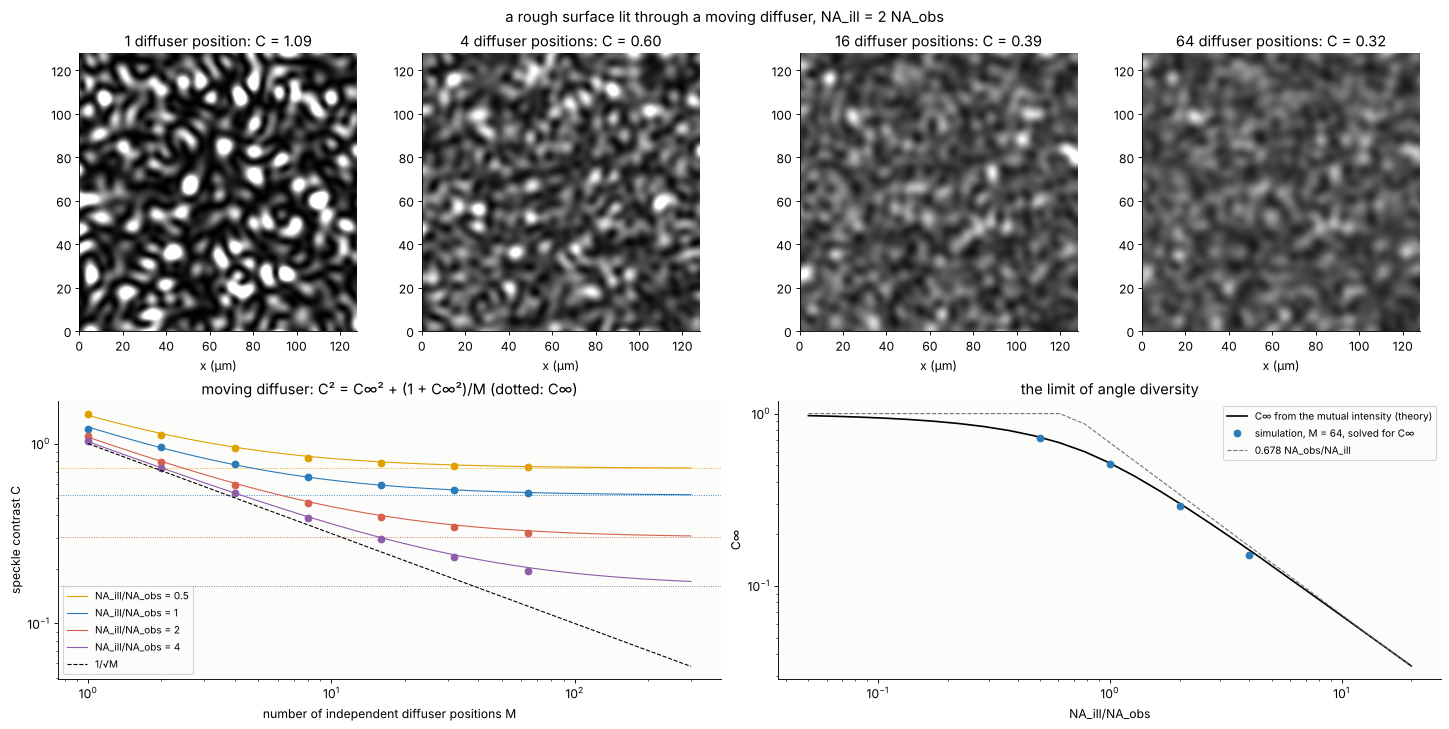

In [15]:
fig = plt.figure(figsize=(18, 9), layout="constrained")
fig.suptitle("a rough surface lit through a moving diffuser, NA_ill = 2 NA_obs")
gs = fig.add_gridspec(2, 4)
for k, m in enumerate((1, 4, 16, 64)):
    a = fig.add_subplot(gs[0, k])
    I = snaps[m]
    a.imshow(I/I.mean(), extent=ext, cmap="gray", vmin=0, vmax=3, origin="lower")
    a.set_xlim(0, 128)
    a.set_ylim(0, 128)
    a.set_title("{} diffuser position{}: C = {:.2f}".format(m, "s" if m > 1 else "", sp.speckle_contrast(I)))
    a.set_xlabel("x (µm)")
a = fig.add_subplot(gs[1, :2])
mm = np.logspace(0, np.log10(300), 100)
for q, c in zip(ratios, (ORANGE, BLUE, RED, PURPLE)):
    a.loglog(Ms5, C_M[q], "o", color=c)
    a.loglog(mm, sp.moving_diffuser_contrast(mm, C_inf[q]), color=c, lw=1, label="NA_ill/NA_obs = {:g}".format(q))
    a.axhline(C_inf[q], color=c, ls=":", lw=0.8)
a.loglog(mm, 1/np.sqrt(mm), color="k", ls="--", lw=1, label="1/√M")
a.set_xlabel("number of independent diffuser positions M")
a.set_ylabel("speckle contrast C")
a.set_title("moving diffuser: C² = C∞² + (1 + C∞²)/M (dotted: C∞)")
a.legend(fontsize=9, loc="lower left")
a = fig.add_subplot(gs[1, 2:])
a.loglog(q_th, C_inf_curve, color="k", label="C∞ from the mutual intensity (theory)")
C64 = np.array([C_M[q][-1] for q in ratios])
a.loglog(ratios, np.sqrt((C64**2 - 1/64)/(1 + 1/64)), "o", color=BLUE, label="simulation, M = 64, solved for C∞")
a.loglog(q_th, np.minimum(1, sp.ANGULAR_LIMIT/q_th), color=GREY, ls="--", lw=1, label="0.678 NA_obs/NA_ill")
a.set_xlabel("NA_ill/NA_obs")
a.set_ylabel("C∞")
a.set_title("the limit of angle diversity")
a.legend(fontsize=9)
plt.show()

The simulation (dots) follows both formulas. For $M = 1$ the contrast is
1.03 to 1.47, above that of plain speckle, and largest when
$\mathrm{NA_{ill}} < \mathrm{NA_{obs}}$. In that case the coarse
illumination grains multiply the fine object grains, which the
one-position image shows. More positions help as $1/\sqrt M$ at first,
then level off at $C_\infty$. At $\mathrm{NA_{ill}} = 2\,\mathrm{NA_{obs}}$,
64 positions give 0.32, and no number of positions gets below
$C_\infty = 0.30$, however fast the diffuser spins. The theory for $C_\infty$ reaches 0.683 $\mathrm{NA_{obs}}/\mathrm{NA_{ill}}$
at a ratio of 20, on its way to the limit 0.678.

The lesson for design: the illumination must fill a large angle *as seen
from the object*, compared with the observer's aperture. In a
homogenizer (notebook 86) this angle is the size of the illuminated
pupil. A moving diffuser fills it with independent patterns over time,
and a fly's eye spreads its channels across it. With coherent light the
channels interfere instead (notebook 86, section 4), and the moving
diffuser is what makes them independent.

## 6. A speckle budget for a laser projector

A viewer looks at a screen lit by a laser projector. Seen from a point on
the screen, the projection lens of aperture $D$ fills
$\mathrm{NA_{ill}} = D/(2z)$, if a moving diffuser inside the projector
fills its pupil, and the eye pupil $d$ fills
$\mathrm{NA_{obs}} = d/(2z)$. With both at the same distance, the ratio is
simply $D/d$. A viewer closer to the screen than the projector sees
*more* speckle.

The eye integrates for roughly 50 ms (an assumption: the value depends on
brightness and the observer). In that time the diffuser has to produce
enough independent patterns to approach $C_\infty$. From the formula of
section 5, coming within 10 % of $C_\infty$ takes
$M \ge (1 + C_\infty^2)/(0.21\,C_\infty^2)$ positions. The mechanisms
are independent, so their contrasts multiply.

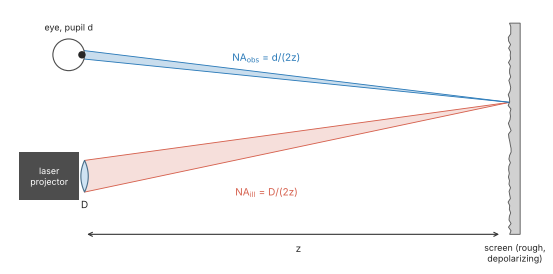

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.2))
sketch.laser_projector(ax)
plt.show()

In [17]:
z, d_eye, t_eye = 3.0, 3e-3, 0.05            # m, m, s
NA_obs6 = d_eye/(2*z)
print("eye at {:.0f} m, pupil {:.0f} mm: NA_obs = {:.1e}".format(z, 1e3*d_eye, NA_obs6))
rows = []
for D in (5e-3, 20e-3, 50e-3):
    NA_ill6 = D/(2*z)
    C_ang = sp.angular_diversity_contrast(NA_ill6, NA_obs6, WL*1e-6, n=2048)
    M_need = (1 + C_ang**2)/(0.21*C_ang**2)            # C within 10 % of C_inf
    rows.append((D, NA_ill6, C_ang, M_need))
    print("lens aperture {:2.0f} mm: NA_ill/NA_obs = {:4.1f}, C_angle = {:.3f}, needs M = {:.0f} positions "
          "({:.0f} per second) to come within 10 % of it".format(1e3*D, NA_ill6/NA_obs6, C_ang, M_need, M_need/t_eye))
C_ang20 = rows[1][2]
budget = [("angle (20 mm lens, enough positions)", C_ang20),
          ("polarization (depolarizing screen)", sp.polarization_contrast(0.0)),
          ("wavelength: 1 nm FWHM laser, surface σ_h = 5 µm", sp.spectral_contrast(1e-3/2.355, WL, 10.0)),
          ("wavelength: 1 nm FWHM laser, volume σ_L = 0.3 mm", sp.spectral_contrast(1e-3/2.355, WL, 300.0))]
for name, c in budget:
    print("{:52s} C = {:.3f}".format(name, c))
C_total_surf = budget[0][1]*budget[1][1]*budget[2][1]
C_total_vol = budget[0][1]*budget[1][1]*budget[3][1]
print("product, surface screen: {:.3f}; volume scattering screen: {:.3f}".format(C_total_surf, C_total_vol))

eye at 3 m, pupil 3 mm: NA_obs = 5.0e-04


lens aperture  5 mm: NA_ill/NA_obs =  1.7, C_angle = 0.350, needs M = 44 positions (871 per second) to come within 10 % of it


lens aperture 20 mm: NA_ill/NA_obs =  6.7, C_angle = 0.099, needs M = 492 positions (9838 per second) to come within 10 % of it


lens aperture 50 mm: NA_ill/NA_obs = 16.7, C_angle = 0.041, needs M = 2873 positions (57468 per second) to come within 10 % of it
angle (20 mm lens, enough positions)                 C = 0.099
polarization (depolarizing screen)                   C = 0.707
wavelength: 1 nm FWHM laser, surface σ_h = 5 µm      C = 0.991
wavelength: 1 nm FWHM laser, volume σ_L = 0.3 mm     C = 0.417
product, surface screen: 0.069; volume scattering screen: 0.029


For a 3 mm eye pupil at 3 m (NA $5\times10^{-4}$):

| lens aperture | NA_ill/NA_obs | $C_\infty$ (angle) | positions for $1.1\,C_\infty$ | per second |
|---|---|---|---|---|
| 5 mm | 1.7 | 0.35 | 44 | ~900 |
| 20 mm | 6.7 | 0.099 | 492 | ~10 000 |
| 50 mm | 16.7 | 0.041 | 2873 | ~57 000 |

The budget for the 20 mm lens:

- angle: 0.099,
- depolarizing screen: 0.707,
- a 1 nm wide laser on a surface-scattering screen ($\sigma_h = 5$ µm):
  0.991, practically nothing,
- the same laser on a screen with volume scattering ($\sigma_L = 0.3$ mm,
  assumed): 0.417.

The product is 6.9 % for the surface screen and 2.9 % for the volume
screen. A contrast of a few per cent is commonly quoted as the limit of
visibility. Reaching it takes all three mechanisms at once: a wide
projection aperture with a diffuser that decorrelates some ten thousand
times a second, a depolarizing screen, and a laser that is broad (or has
several lines) on a screen whose paths are spread over a fraction of a
millimetre.

## Summary

- Fully developed speckle has an exponential intensity distribution,
  contrast 1 and grains of radius $0.61\lambda/\mathrm{NA}$ (the Airy
  zero). Above roughness of about $\lambda/4$ the surface no longer
  matters.
- Only the sum of uncorrelated patterns lowers the contrast:
  $C = 1/\sqrt M$ for independent ones, and
  $C = \sqrt{\sum\lambda_n^2}/\sum\lambda_n$ (the eigenvalues of the field
  correlation matrix) for correlated ones.
- Polarization: at most $1/\sqrt2$, and only on depolarizing surfaces;
  $C = \sqrt{(1 + P^2)/2}$.
- Wavelength: $|\mu|^2 = \exp(-(\Delta k\sigma_L)^2)$ with the rms path
  spread $\sigma_L$, and
  $C = (1 + (4\pi\sigma_L\sigma_\lambda/\lambda^2)^2)^{-1/4}$ for a
  Gaussian spectrum. It works well for volume scatterers and fibres, and
  hardly at all for surfaces with micrometre roughness.
- Angle: a moving diffuser gives $C_M^2 = C_\infty^2 + (1 + C_\infty^2)/M$.
  The limit $C_\infty$ is set by $\mathrm{NA_{ill}}/\mathrm{NA_{obs}}$
  (about $0.678\,\mathrm{NA_{obs}}/\mathrm{NA_{ill}}$), and a diffuser that
  stands still gives product speckle with $C > 1$.
- In a projector the mechanisms multiply. A contrast of a few per cent
  needs all of them.

In [18]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 40 s


## References

- J. W. Goodman, *Speckle Phenomena in Optics: Theory and Applications*,
  2nd ed., SPIE Press (2020).
- J. W. Goodman, "Some fundamental properties of speckle", J. Opt. Soc.
  Am. 66, 1145–1150 (1976).
- J. I. Trisnadi, "Speckle contrast reduction in laser projection
  displays", Proc. SPIE 4657, 131–137 (2002).
- S. Roelandt, Y. Meuret, G. Craggs, G. Verschaffelt, P. Janssens and
  H. Thienpont, "Standardized speckle measurement method matched to human
  speckle perception in laser projection systems", Opt. Express 20,
  8770–8783 (2012).